## <font color='Darkred'>**Problem statement**</font>
<hr>

- "Subsidy Inc. delivers subsidies to individuals based on their income ·Accurate income data is one of the hardest piece of data to obtain across the world
- Subsidy Inc. has obtained a large data set of authenticated data on individual
  income, demographic parameters,and a few financial parameters.
- Subsidy Inc. wishes us to:
  Develop an income classifier system for individuals.
- <font color='Darkred'>**The Objective is to:**</font>
  - Simplify the data system by reducing the number of variables to be studied, without sacrificing too much of accuracy. Suchasystem would help Subsidy Inc. in planning subsidy outlay, monitoring and preventing misuse.

- 
  -  Method identification
    -
      - •Logistic Regression
      - Random Forest
      -   •KNearest Neighbors
  - •Realization of solution
    - •Evaluate performance metrics
    - If assumptions are satisfied and solutions are acceptable then model is good

-  <font color='Darkgreen' size='4'>**Classifying Personal Income**</font>

In [102]:
#  -*- coding: utf-8 -*-
#  To work with dataframes
import pandas as pd
#  To perform numerical operations
import numpy as np
#  To visualize data
import seaborn as sns
#  To partition the data
from sklearn.model_selection import train_test_split
# Importing library for logistic regression 
from sklearn.linear_model import LogisticRegression
# Importing performamce metrices - accuracy score & confusion matrix
from sklearn.metrics import accuracy_score,confusion_matrix
import matplotlib.pyplot as plt


In [103]:
data_income = pd.read_csv('ds_salaries.csv')
data=data_income.copy()

- Exploratory data analysis:
    - 1.Getting to know the data 
    - 2.Data preprocessing (<issing values)
    - 3.Cross tables and data visualization


- To check the variables data type
    - **print(data_income.info())**
- checking for the missing values
    - **data_income.isnull()**

In [104]:
# data_income.isnull()
# print(data_income.info())
print('Data columns with null values: \n', data_income.isnull().sum())

Data columns with null values: 
 work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64


- Summary of numerical variables 

In [105]:
summary_num = data_income.describe()
print(summary_num)

         work_year        salary  salary_in_usd  remote_ratio
count  3755.000000  3.755000e+03    3755.000000   3755.000000
mean   2022.373635  1.906956e+05  137570.389880     46.271638
std       0.691448  6.716765e+05   63055.625278     48.589050
min    2020.000000  6.000000e+03    5132.000000      0.000000
25%    2022.000000  1.000000e+05   95000.000000      0.000000
50%    2022.000000  1.380000e+05  135000.000000      0.000000
75%    2023.000000  1.800000e+05  175000.000000    100.000000
max    2023.000000  3.040000e+07  450000.000000    100.000000


- 1. Summary of categorical variables 
- 2. Frequency of each categories
- 3. Checking for unique classes 

In [106]:
#1. summary_cate = data_income.describe(include = "0")
# print(summary_cate)
# 2.
data_income1 = pd.read_csv('ds_salaries.csv')
data=data_income1.copy()
data['work_year'].value_counts()
data['salary'].value_counts()

100000    112
150000    100
120000     99
160000     85
130000     85
         ... 
241871      1
93919       1
385000      1
225900      1
412000      1
Name: salary, Length: 815, dtype: int64

In [107]:
# 3.
print(np.unique(data_income['work_year']))
print(np.unique(data_income['salary']))

[2020 2021 2022 2023]
[    6000     7000     7500     8000     8760     9272    10000    12000
    13000    13400    14000    15000    18000    19000    20000    21000
    21600    21844    22000    22800    23000    24000    25000    25500
    26000    27000    28500    29000    30000    31000    32000    32400
    33000    34000    34320    35000    36000    36050    37000    37456
    38000    38400    39600    40000    40300    40900    41000    42000
    43200    44000    44737    45000    45555    45600    45760    46000
    47000    47500    48000    49500    50000    51000    51400    51962
    51999    52000    52500    52800    53000    54000    55000    55250
    56000    56100    57000    58000    59000    60000    60027    60400
    61000    61200    61300    61500    61800    62000    62500    63000
    63900    64000    64200    64500    64980    65000    65004    65488
    65720    66000    66100    66500    66822    67000    68000    68400
    69000    69600    69999  

- There exists_____'?'_______ instead of nan
    - Go back and read the data by including "na_values['?']" to consider '?' aas nan

In [108]:
data_income=pd.read_csv('ds_salaries.csv',na_values=["?"])

- Data pre-processing 

In [109]:
data_income.isnull().sum()
# sns.pairplot(data_income, kind="scatter", hue="city")
# plt.show()

work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

In [110]:
missing = data_income[data_income.isnull().any(axis=1)]
#  axis = 1 => to consider at least one column value is missing 

In [111]:
data_income1 = data_income.dropna(axis=0)
#  Realtionship between independent variales
# correlation = data_income1.corr() 
correlation = data_income1.corr(numeric_only=True)
#  Correlation values between -1 to +1

- **if you don't specify the numeric_only parameter, it defaults to False. This means that when calculating the correlation, all columns in the DataFrame are considered, regardless of their data types**

- Cross tables & Data visualization 
    - 

In [112]:
#  Extracting the column names 
data_income1.columns

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary', 'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size'],
      dtype='object')

- Gender/Metcolor proportion table:


In [113]:
data1 = pd.read_csv('Toyota.csv')
data=data1.copy()
MetColor = pd.crosstab(index=data1["MetColor"], columns='count', normalize=True)
print(MetColor)

col_0        count
MetColor          
0         0.461538
1         0.538462


- KM vs Price status :

In [114]:
Price_KM = pd.crosstab(index=data1["Price"], columns=data1["KM"], margins=True, normalize='index')
print(Price_KM)
#  includes row and columns total

KM        40234     61000
Price                    
11456  0.333333  0.666667
13600  0.571429  0.428571
All    0.461538  0.538462


- Frequency distribution of 'Price'

'\n69% of cars Price status is <= 11456\n& 60% of cars Price status is > 12000\n'

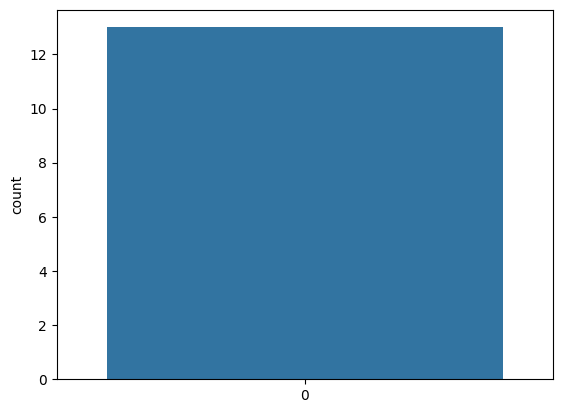

In [115]:
Price = sns.countplot(data1['Price'])
"""
69% of cars Price status is <= 11456
& 60% of cars Price status is > 12000
"""

- Histogram of Age 

C:\Users\ANKIT DIMRI\AppData\Local\Temp\ipykernel_22284\384820747.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data1['KM'], bins=10,kde=False)


<AxesSubplot: xlabel='KM'>

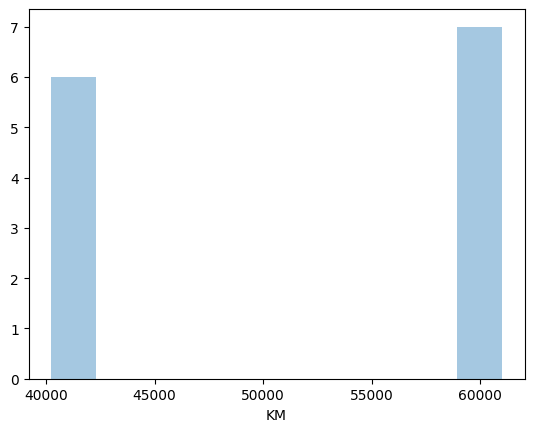

In [116]:
sns.distplot(data1['KM'], bins=10,kde=False)

- Box plot Price vs KM

In [ ]:
sns.boxplot('Price', 'KM',data=data1)
data1.groupby('Price')['KM'].median()

- Case Study - Classification 
    - 
    - Logistic Regression 
        -

In [ ]:
#  Reindexing the salary status names to 0,1
data_income = pd.read_csv('Salary_Data.csv')
data1=data_income.copy()
# data1['Salary']=data1['Salary'].map({'Less than or equal to 50,000':0,'Greater than or equal to 50,000':1})
print(data1['Salary'])

0      39343
1      46205
2      37731
3      43525
4      39891
5      56642
6      60150
7      54445
8      64445
9      57189
10     63218
11     55794
12     56957
13     57081
14     61111
15     67938
16     66029
17     83088
18     81363
19     93940
20     91738
21     98273
22    101302
23    113812
24    109431
25    105582
26    116969
27    112635
28    122391
29    121872
Name: Salary, dtype: int64


In [ ]:
new_data=pd.get_dummies(data1, drop_first=True)

In [ ]:
# sns.boxplot('Salary', 'YearsExperience',data=data1)
# data1.groupby('Salary')['YearsExperience'].median()

In [ ]:
#  sorting the column names 
columns_list = list(new_data.columns)
print(columns_list)

['YearsExperience', 'Salary']


In [ ]:
#  Separating the input names from data
features = list(set(columns_list)-set(['Salary']))
print(features)

['YearsExperience']


In [ ]:
y=new_data['Salary'].values
print(y)

[ 39343  46205  37731  43525  39891  56642  60150  54445  64445  57189
  63218  55794  56957  57081  61111  67938  66029  83088  81363  93940
  91738  98273 101302 113812 109431 105582 116969 112635 122391 121872]


In [ ]:
#  Sorting the values from input features
x=new_data[features].values
print(x)

[[ 1.1]
 [ 1.3]
 [ 1.5]
 [ 2. ]
 [ 2.2]
 [ 2.9]
 [ 3. ]
 [ 3.2]
 [ 3.2]
 [ 3.7]
 [ 3.9]
 [ 4. ]
 [ 4. ]
 [ 4.1]
 [ 4.5]
 [ 4.9]
 [ 5.1]
 [ 5.3]
 [ 5.9]
 [ 6. ]
 [ 6.8]
 [ 7.1]
 [ 7.9]
 [ 8.2]
 [ 8.7]
 [ 9. ]
 [ 9.5]
 [ 9.6]
 [10.3]
 [10.5]]


In [ ]:
#  Splitting the data into train and test
train_x,test_x,train_y,test_y=train_test_split(x,y,test_size=0.3,random_state=0)

In [ ]:
#  Make an instance of the model
logistic = LogisticRegression()

In [ ]:
#  Fitting the values for x and y
logistic.fit(train_x,train_y)
logistic.coef_
logistic.intercept_

c:\Users\user\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:444: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


array([ 4.24565683,  3.09932062,  3.30743983,  4.0379282 ,  2.07095226,
        2.37738416,  1.25777763,  1.56264279,  2.27506936,  0.74618989,
        2.07095226,  0.11841171,  0.33003893, -0.76313893, -1.85427513,
       -0.87831881, -2.25088495, -3.4207378 , -5.39652423, -3.91160269,
       -9.02428194])

In [ ]:
# Prediction from test data
prediction = logistic.predict(test_x)
print(prediction)

[ 39343 121872  56957  57189 121872 121872 121872  57189  66029]


In [ ]:
#  Confusion Matrix 
confusion_matrix=confusion_matrix(test_y,prediction)
print(confusion_matrix)
# 24-may-2022 up

[[0 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 1 0]]


In [ ]:
#  Calculating the accuracy 
accuracy_score = accuracy_score(test_y, prediction)
print(accuracy_score)

0.0


- Printing the misclassified values from predcition 

In [ ]:
print('Misclassified samples: %d' % (test_y != prediction).sum())

Misclassified samples: 9


- **Logistic Regression - Removing INsignificant Variables** 
    -
- Reindexing the Price status names to 0,1


In [ ]:
data_income_1 = pd.read_csv('Toyota.csv')
data_1=data_income_1.copy()
data_1['KM']=data_1['KM'].map({'Less than or equal to 50,000':0,'Greater than or equal to 50,000':1})
print(data_1['KM'])

0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
5    NaN
6    NaN
7    NaN
8    NaN
9    NaN
10   NaN
11   NaN
12   NaN
Name: KM, dtype: float64


In [ ]:
col=['Age','HP','Automatic','Price']
new_data_2=data_1.drop(col,axis=1)


In [ ]:
new_data_2=pd.get_dummies(new_data_2,drop_first=True)

In [ ]:
# Storing the column names 
columns_list=list(new_data_2.columns)
print(columns_list)

['Unnamed: 0', 'KM', 'MetColor', 'CC', 'Weight', 'FuelType_Petrol', 'Doors_3', 'Doors_three']


In [ ]:
#  Separating the input names from data
features = list(set(columns_list)-set(['KM']))
print(features)

['FuelType_Petrol', 'Doors_3', 'MetColor', 'Unnamed: 0', 'Weight', 'Doors_three', 'CC']


In [ ]:
# storing the output values in y 
x=new_data_2['KM'].values
print(y)

[ 39343  46205  37731  43525  39891  56642  60150  54445  64445  57189
  63218  55794  56957  57081  61111  67938  66029  83088  81363  93940
  91738  98273 101302 113812 109431 105582 116969 112635 122391 121872]


In [ ]:
# storing the output values in x 
x=new_data_2['KM'].values
print(y)

[ 39343  46205  37731  43525  39891  56642  60150  54445  64445  57189
  63218  55794  56957  57081  61111  67938  66029  83088  81363  93940
  91738  98273 101302 113812 109431 105582 116969 112635 122391 121872]


In [ ]:
#  Splitting the data into train and test
train_x,test_x,train_y,test_y = train_test_split(x,y,test_size=0.3, random_state=0)

In [ ]:
#  Make an instance of the model 
logistic=LogisticRegression()

In [ ]:
#  fitting the values for x and y 
logistic.fit(train_x,train_y)

c:\Users\user\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:444: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [ ]:
#  prediction from test data
prediction= logistic.predict(test_x)

In [ ]:
# Calculating the accuracy 
accuracy_score = accuracy_score(test_y, prediction) 

In [ ]:
#  printing the misclassified values from prediction 
print('Misclassified samples : %d' % (test_y != prediction).sum())

Misclassified samples : 9


- **KNN**

In [ ]:
#   importing thhe library of KNN
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
#  import library for plotting 
import matplotlib.pyplot as plt

In [ ]:
#  Storing the K nearest neighbors classifier 
KNN_classifier = KNeighborsClassifier(n_neighbors=5)

In [ ]:
KNN_classifier.fit(train_x,train_y)

KNeighborsClassifier()

In [ ]:
#  predicting the test values with model
prediction=KNN_classifier.predict(test_x)

In [ ]:
# Performance metric check 
confusion_matrix = confusion_matrix(test_x, prediction)
print("\t","Predicted values")
print("Orignal values\n",confusion_matrix)

In [ ]:
# Calculating the accuracy 
accuracy_score = accuracy_score(train_y, prediction)
print(accuracy_score)
print('Misclassified Sample : %d' % (train_y != prediction).sum())
# Effect of K value on classifer
Misclassified_sample=[]
#  Calculating error for k values between 1 and 20
for i in range(1,20):
    knn=KNeighborsClassifier(n_neighbores=i)
    knn.fit(train_x,test_y)
    pred_i = knn.predict(test_x)
    Misclassified_sample.append((train_y != pred_i).sum())
print(Misclassified_sample)